# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** [Isi nama Anda]
- **Email:** [Isi email Anda]
- **ID Dicoding:** [Isi ID Dicoding Anda]

## Menentukan Pertanyaan Bisnis
1. **Pertanyaan 1:** Bagaimana pengaruh **musim** dan **kondisi cuaca** terhadap rata-rata jumlah penyewaan sepeda harian selama periode 2011–2012, dan berapa persen pertumbuhan total penyewaan per bulan dari tahun 2011 ke 2012?
2. **Pertanyaan 2:** Pada jam berapa saja terjadi puncak penyewaan sepeda pada **hari kerja** dibandingkan **hari libur/akhir pekan** sepanjang tahun 2012, dan bagaimana perbedaan pola antara pengguna **casual** dan **registered**?

*Kedua pertanyaan bersifat SMART: spesifik (musim/cuaca, jam & tipe hari), terukur (rata-rata, persentase, jumlah), action-oriented (penentuan stok armada, jadwal perawatan, promosi), relevan dengan bisnis rental sepeda, dan terikat waktu (2011–2012 / 2012).*

## Import Semua Packages/Library yang Digunakan

In [1]:
import calendar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

## Data Wrangling
### Gathering Data

In [2]:
day_df = pd.read_csv("data/day.csv")
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [3]:
hour_df = pd.read_csv("data/hour.csv")
hour_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:**
- Dataset terdiri dari dua tabel: `day.csv` (731 baris, data harian) dan `hour.csv` (17.379 baris, data per jam) untuk periode 1 Januari 2011 – 31 Desember 2012.
- Kolom target adalah `cnt` (total penyewaan) = `casual` + `registered`. Kolom kategorikal (season, weathersit, dll.) masih berupa kode angka.

### Assessing Data
#### Menilai tabel `day_df`

In [4]:
day_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 98.6 KB


In [5]:
print("Missing value:\n", day_df.isna().sum())
print("Jumlah duplikasi:", day_df.duplicated().sum())

Missing value:
 instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
Jumlah duplikasi: 0


In [6]:
day_df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


#### Menilai tabel `hour_df`

In [7]:
hour_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     17379 non-null  int64  
 1   dteday      17379 non-null  str    
 2   season      17379 non-null  int64  
 3   yr          17379 non-null  int64  
 4   mnth        17379 non-null  int64  
 5   hr          17379 non-null  int64  
 6   holiday     17379 non-null  int64  
 7   weekday     17379 non-null  int64  
 8   workingday  17379 non-null  int64  
 9   weathersit  17379 non-null  int64  
 10  temp        17379 non-null  float64
 11  atemp       17379 non-null  float64
 12  hum         17379 non-null  float64
 13  windspeed   17379 non-null  float64
 14  casual      17379 non-null  int64  
 15  registered  17379 non-null  int64  
 16  cnt         17379 non-null  int64  
dtypes: float64(4), int64(12), str(1)
memory usage: 2.4 MB


In [8]:
print("Missing value:\n", hour_df.isna().sum())
print("Jumlah duplikasi:", hour_df.duplicated().sum())

Missing value:
 instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
Jumlah duplikasi: 0


In [9]:
hour_df.describe()

,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,17379.0000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000,17379.000000
mean,8690.0000,2.501640,0.502561,6.537775,11.546752,0.028770,3.003683,0.682721,1.425283,0.496987,0.475775,0.627229,0.190098,35.676218,153.786869,189.463088
std,5017.0295,1.106918,0.500008,3.438776,6.914405,0.167165,2.005771,0.465431,0.639357,0.192556,0.171850,0.192930,0.122340,49.305030,151.357286,181.387599
min,1.0000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4345.5000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8690.0000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.194000,17.000000,115.000000,142.000000
75%,13034.5000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.780000,0.253700,48.000000,220.000000,281.000000
max,17379.0000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,1.000000,1.000000,0.850700,367.000000,886.000000,977.000000


In [10]:
# Cek inkonsistensi: apakah cnt == casual + registered?
print("day  :", (day_df['cnt'] != day_df['casual'] + day_df['registered']).sum())
print("hour :", (hour_df['cnt'] != hour_df['casual'] + hour_df['registered']).sum())
# Cek kelengkapan jam: idealnya 731 hari x 24 jam = 17544 baris
print("Baris hour yang hilang:", 731*24 - len(hour_df))

day  : 0
hour : 0
Baris hour yang hilang: 165


In [11]:
# Cek outlier dengan metode IQR dan nilai invalid
for col in ['temp', 'hum', 'windspeed']:
    q1, q3 = day_df[col].quantile([.25, .75]); iqr = q3 - q1
    n = ((day_df[col] < q1 - 1.5*iqr) | (day_df[col] > q3 + 1.5*iqr)).sum()
    print(f"{col}: {n} outlier")
print("Hari dengan hum = 0:", (day_df['hum'] == 0).sum())
print("Jam dengan hum = 0 :", (hour_df['hum'] == 0).sum())

temp: 0 outlier
hum: 2 outlier
windspeed: 13 outlier
Hari dengan hum = 0: 1
Jam dengan hum = 0 : 22


**Insight:**
- **Tipe data tidak sesuai:** kolom `dteday` bertipe `object`, seharusnya `datetime`.
- **Inconsistent/kurang informatif:** kolom kategorikal (`season`, `yr`, `weekday`, `workingday`, `weathersit`) disimpan sebagai kode angka sehingga sulit dibaca.
- **Missing value & duplikasi:** tidak ditemukan; `cnt` selalu konsisten dengan `casual + registered`.
- **Data tidak lengkap:** `hour_df` kehilangan 165 baris jam (jam tanpa catatan). Tidak perlu diisi karena analisis menggunakan agregasi rata-rata.
- **Invalid value/outlier:** terdapat nilai `hum = 0` (kelembapan 0% tidak realistis) serta beberapa outlier `windspeed`.

**Solusi untuk tahap cleaning:** ubah `dteday` ke datetime, ubah kode kategori menjadi label, dan ganti nilai `hum = 0` dengan median. Outlier windspeed dibiarkan karena merupakan kejadian cuaca nyata.

### Cleaning Data

In [12]:
for df in [day_df, hour_df]:
    df['dteday'] = pd.to_datetime(df['dteday'])
    df['season'] = df['season'].map({1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'})
    df['yr'] = df['yr'].map({0: 2011, 1: 2012})
    df['weathersit'] = df['weathersit'].map({1: 'Clear', 2: 'Mist/Cloudy', 3: 'Light Rain/Snow', 4: 'Heavy Rain/Snow'})
    df['weekday'] = df['dteday'].dt.day_name()
    df['workingday'] = df['workingday'].map({0: 'Holiday/Weekend', 1: 'Working Day'})
    # Ganti nilai hum = 0 (invalid) dengan median
    med = df.loc[df['hum'] > 0, 'hum'].median()
    df.loc[df['hum'] == 0, 'hum'] = med

day_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[us]
 2   season      731 non-null    str           
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    str           
 7   workingday  731 non-null    str           
 8   weathersit  731 non-null    str           
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[us](1), float64(4), int

In [13]:
print("hum = 0 tersisa:", (day_df['hum'] == 0).sum(), (hour_df['hum'] == 0).sum())
day_df.head()

hum = 0 tersisa: 0 0


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,Spring,2011,1,0,Saturday,Holiday/Weekend,Mist/Cloudy,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,Spring,2011,1,0,Sunday,Holiday/Weekend,Mist/Cloudy,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,Spring,2011,1,0,Monday,Working Day,Clear,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,Spring,2011,1,0,Tuesday,Working Day,Clear,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,Spring,2011,1,0,Wednesday,Working Day,Clear,0.226957,0.229270,0.436957,0.186900,82,1518,1600


**Insight:**
- `dteday` kini bertipe datetime dan seluruh kolom kategori sudah berlabel sehingga lebih mudah dianalisis dan divisualisasikan.
- Nilai kelembapan 0 yang tidak valid sudah diganti dengan median.

## Exploratory Data Analysis (EDA)
### Explore statistik umum

In [14]:
day_df[['temp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']].describe()

,temp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,0.495385,0.628752,0.190486,848.176471,3656.172367,4504.348837
std,0.183051,0.140518,0.077498,686.622488,1560.256377,1937.211452
min,0.059130,0.187917,0.022392,2.000000,20.000000,22.000000
25%,0.337083,0.521041,0.134950,315.500000,2497.000000,3152.000000
50%,0.498333,0.627083,0.180975,713.000000,3662.000000,4548.000000
75%,0.655417,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,0.861667,0.972500,0.507463,3410.000000,6946.000000,8714.000000


In [15]:
day_df[['temp', 'atemp', 'hum', 'windspeed', 'cnt']].corr()['cnt'].sort_values(ascending=False)

cnt          1.000000
atemp        0.631066
temp         0.627494
hum         -0.114276
windspeed   -0.234545
Name: cnt, dtype: float64

### Explore pengaruh musim & cuaca (Pertanyaan 1)

In [16]:
day_df.groupby('season')['cnt'].agg(['mean', 'median', 'min', 'max', 'sum']).sort_values('mean', ascending=False)

,mean,median,min,max,sum
season,,,,,
Fall,5644.303191,5353.5,1115,8714,1061129
Summer,4992.331522,4941.5,795,8362,918589
Winter,4728.162921,4634.5,22,8555,841613
Spring,2604.132597,2209.0,431,7836,471348


In [17]:
day_df.groupby('weathersit')['cnt'].agg(['count', 'mean', 'sum']).sort_values('mean', ascending=False)

,count,mean,sum
weathersit,,,
Clear,463,4876.786177,2257952
Mist/Cloudy,247,4035.862348,996858
Light Rain/Snow,21,1803.285714,37869


In [18]:
monthly = day_df.pivot_table(index='mnth', columns='yr', values='cnt', aggfunc='sum')
monthly['growth_%'] = ((monthly[2012] - monthly[2011]) / monthly[2011] * 100).round(1)
monthly

yr,2011,2012,growth_%
mnth,,,
1,38189,96744,153.3
2,48215,103137,113.9
3,64045,164875,157.4
4,94870,174224,83.6
5,135821,195865,44.2
6,143512,202830,41.3
7,141341,203607,44.1
8,136691,214503,56.9
9,127418,218573,71.5


In [19]:
yearly = day_df.groupby('yr')['cnt'].sum()
print(yearly)
print(f"Pertumbuhan tahunan: {(yearly[2012] / yearly[2011] - 1) * 100:.1f}%")

yr
2011    1243103
2012    2049576
Name: cnt, dtype: int64
Pertumbuhan tahunan: 64.9%


### Explore pola per jam (Pertanyaan 2)

In [20]:
h2012 = hour_df[hour_df['yr'] == 2012]
hourly = h2012.groupby(['workingday', 'hr'])[['casual', 'registered', 'cnt']].mean().round(1)
for wd in ['Working Day', 'Holiday/Weekend']:
    print(wd, "- 3 jam puncak:")
    print(hourly.loc[wd].sort_values('cnt', ascending=False).head(3), "\n")

Working Day - 3 jam puncak:


    casual  registered    cnt
hr                           
17    69.8       586.4  656.2
18    60.9       556.1  617.0
8     24.3       580.2  604.5 

Holiday/Weekend - 3 jam puncak:


    casual  registered    cnt
hr                           
13   162.9       296.0  458.9
12   151.8       299.2  451.0
14   167.8       280.1  447.9 



In [21]:
share = h2012.groupby('workingday')[['casual', 'registered']].sum()
(share.div(share.sum(axis=1), axis=0) * 100).round(1)

,casual,registered
workingday,,
Holiday/Weekend,30.6,69.4
Working Day,12.9,87.1


**Insight:**
- Musim **Fall** memiliki rata-rata penyewaan tertinggi, sedangkan **Spring** terendah. Suhu (`temp`) berkorelasi positif cukup kuat (~0,63) dengan jumlah penyewaan.
- Cuaca **Clear** menghasilkan penyewaan terbanyak; pada kondisi **Light Rain/Snow** rata-rata penyewaan turun drastis.
- Total penyewaan 2012 naik sekitar 64,9% dibanding 2011, dengan pertumbuhan terbesar di awal tahun (Q1).
- Hari kerja memiliki dua puncak (08.00 dan 17.00–18.00) yang didominasi pengguna registered (komuter), sedangkan hari libur memiliki satu puncak siang (12.00–14.00) dengan porsi pengguna casual yang jauh lebih besar.

## Visualization & Explanatory Analysis
### Pertanyaan 1: Pengaruh musim & cuaca, serta pertumbuhan bulanan 2011 → 2012

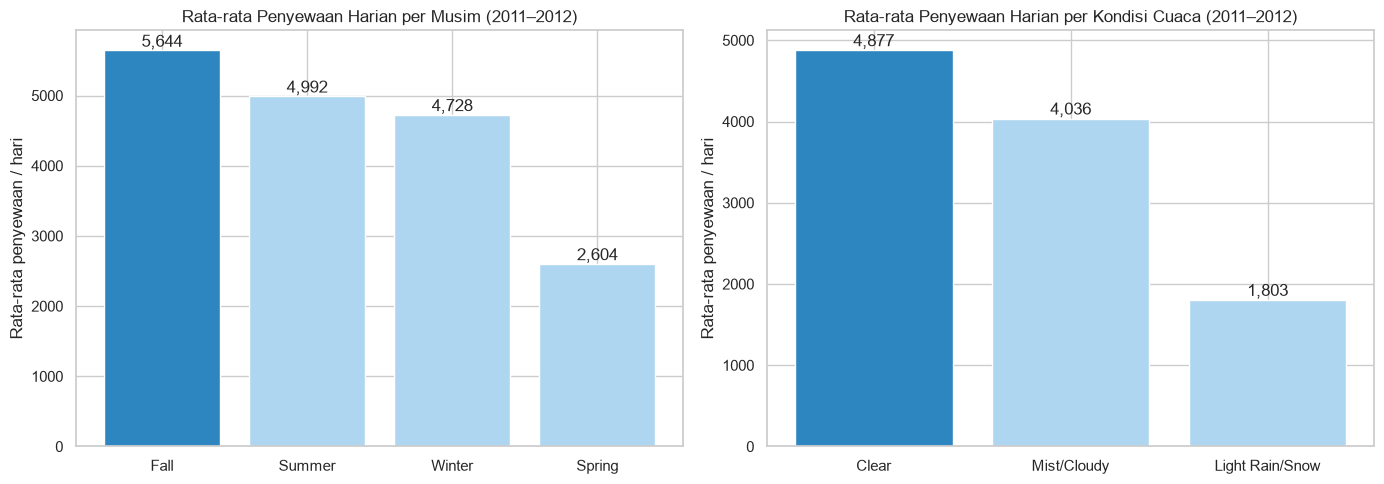

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
s = day_df.groupby('season')['cnt'].mean().sort_values(ascending=False)
w = day_df.groupby('weathersit')['cnt'].mean().sort_values(ascending=False)
for a, data, title in [(ax[0], s, 'Musim'), (ax[1], w, 'Kondisi Cuaca')]:
    colors = ['#2E86C1'] + ['#AED6F1'] * (len(data) - 1)
    a.bar(data.index, data.values, color=colors)
    a.set_title(f'Rata-rata Penyewaan Harian per {title} (2011–2012)')
    a.set_ylabel('Rata-rata penyewaan / hari')
    for i, v in enumerate(data.values):
        a.text(i, v + 50, f'{v:,.0f}', ha='center')
plt.tight_layout(); plt.show()

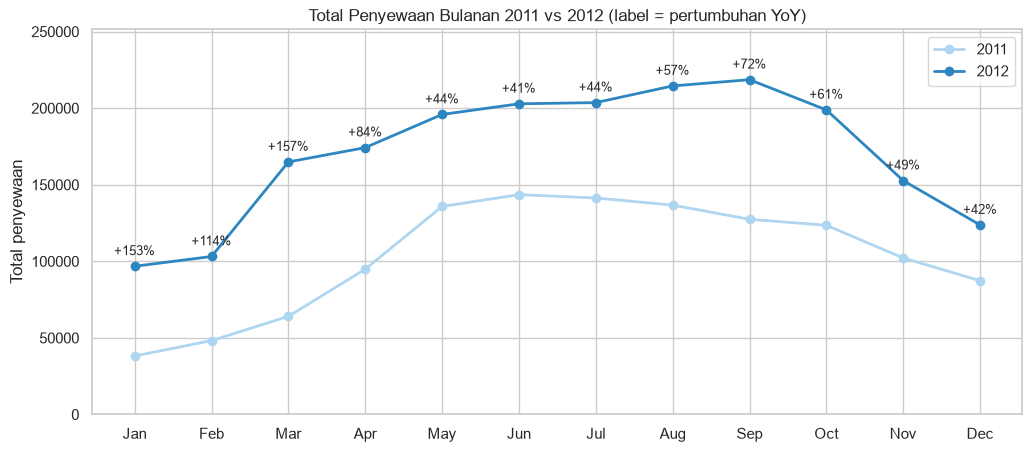

In [23]:
fig, ax = plt.subplots(figsize=(12, 5))
months = [calendar.month_abbr[m] for m in monthly.index]
ax.plot(months, monthly[2011], marker='o', color='#AED6F1', label='2011', linewidth=2)
ax.plot(months, monthly[2012], marker='o', color='#2E86C1', label='2012', linewidth=2)
for i, g in enumerate(monthly['growth_%']):
    ax.annotate(f'+{g:.0f}%', (i, monthly[2012].iloc[i]), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=9)
ax.set_title('Total Penyewaan Bulanan 2011 vs 2012 (label = pertumbuhan YoY)')
ax.set_ylabel('Total penyewaan'); ax.set_ylim(0, monthly[2012].max() * 1.15); ax.legend()
plt.show()

### Pertanyaan 2: Pola penyewaan per jam, hari kerja vs hari libur (2012)

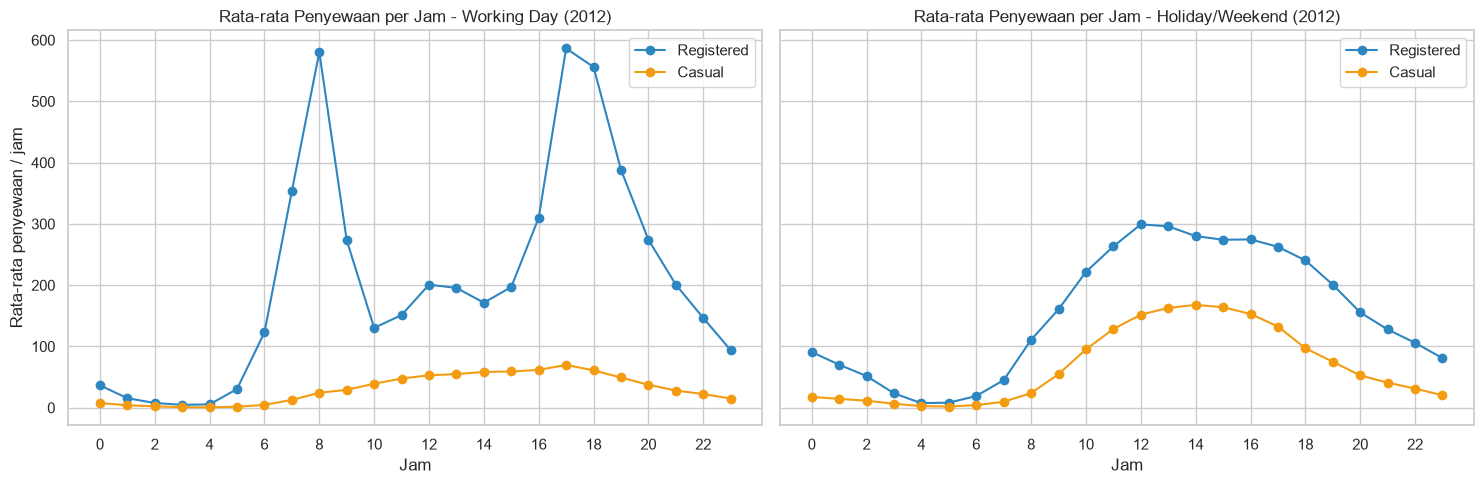

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for a, wd in zip(ax, ['Working Day', 'Holiday/Weekend']):
    d = hourly.loc[wd]
    a.plot(d.index, d['registered'], color='#2E86C1', marker='o', label='Registered')
    a.plot(d.index, d['casual'], color='#F39C12', marker='o', label='Casual')
    a.set_title(f'Rata-rata Penyewaan per Jam - {wd} (2012)')
    a.set_xlabel('Jam'); a.set_xticks(range(0, 24, 2)); a.legend()
ax[0].set_ylabel('Rata-rata penyewaan / jam')
plt.tight_layout(); plt.show()

**Insight:**
- Visualisasi pertama menegaskan bahwa musim Fall dan cuaca Clear adalah kondisi paling ramai; cuaca hujan/salju ringan menurunkan penyewaan lebih dari 60% dibanding cuaca cerah.
- Seluruh bulan pada 2012 tumbuh positif dibanding 2011; pertumbuhan terbesar terjadi pada Januari–Maret.
- Visualisasi kedua menunjukkan pola komuter (puncak 08.00 & 17.00–18.00) pada hari kerja, sedangkan hari libur membentuk kurva rekreasi di siang hari.

## Analisis Lanjutan: Clustering dengan Binning (Manual Grouping)
**Tujuan:** mengelompokkan jam penyewaan ke dalam kategori **tingkat permintaan** (Low/Medium/High/Peak) dan mengelompokkan hari berdasarkan **kategori suhu**, tanpa algoritma machine learning. Hasilnya membantu operator menentukan jam dan kondisi yang memerlukan penambahan armada.

In [25]:
# Binning jumlah penyewaan per jam menjadi tingkat permintaan
bins = [0, 50, 200, 500, hour_df['cnt'].max()]
labels = ['Low (≤50)', 'Medium (51-200)', 'High (201-500)', 'Peak (>500)']
hour_df['demand_level'] = pd.cut(hour_df['cnt'], bins=bins, labels=labels, include_lowest=True)
hour_df['demand_level'].value_counts().sort_index()

demand_level
Low (≤50)          4876
Medium (51-200)    5908
High (201-500)     5316
Peak (>500)        1279
Name: count, dtype: int64

In [26]:
# Binning suhu (temp ternormalisasi; dikali 41 °C sesuai readme dataset)
day_df['temp_c'] = day_df['temp'] * 41
day_df['temp_group'] = pd.cut(day_df['temp_c'], bins=[0, 10, 20, 30, 41],
                              labels=['Dingin (<10°C)', 'Sejuk (10-20°C)', 'Hangat (20-30°C)', 'Panas (>30°C)'])
temp_grp = day_df.groupby('temp_group', observed=True)['cnt'].agg(['count', 'mean']).round(0)
temp_grp

,count,mean
temp_group,,
Dingin (<10°C),60,1678.0
Sejuk (10-20°C),299,3692.0
Hangat (20-30°C),300,5662.0
Panas (>30°C),72,5410.0


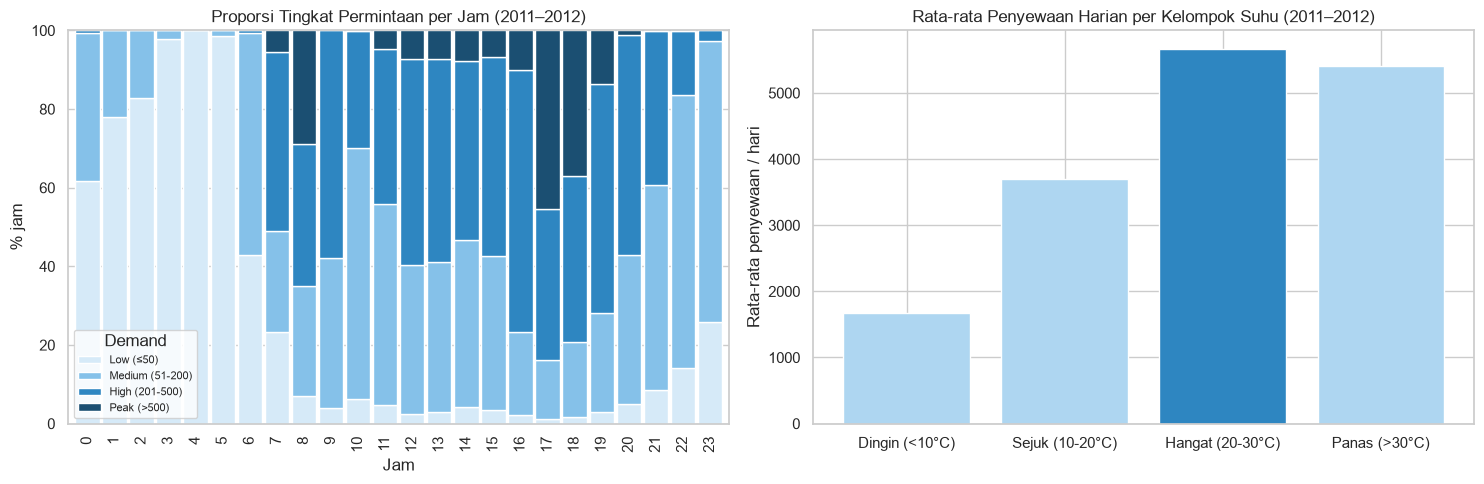

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ct = pd.crosstab(hour_df['hr'], hour_df['demand_level'], normalize='index') * 100
ct.plot(kind='bar', stacked=True, ax=ax[0], color=['#D6EAF8', '#85C1E9', '#2E86C1', '#1B4F72'], width=0.9)
ax[0].set_title('Proporsi Tingkat Permintaan per Jam (2011–2012)')
ax[0].set_ylabel('% jam'); ax[0].set_xlabel('Jam'); ax[0].legend(title='Demand', fontsize=8)
top = temp_grp['mean'].idxmax()
ax[1].bar(temp_grp.index.astype(str), temp_grp['mean'],
          color=['#2E86C1' if i == top else '#AED6F1' for i in temp_grp.index])
ax[1].set_title('Rata-rata Penyewaan Harian per Kelompok Suhu (2011–2012)')
ax[1].set_ylabel('Rata-rata penyewaan / hari')
plt.tight_layout(); plt.show()

**Insight:**
- Status **Peak (>500/jam)** hampir hanya terjadi pada jam 08.00 dan 17.00–18.00.
- Hari dengan suhu hangat memiliki rata-rata penyewaan tertinggi, sedangkan hari dingin (<10°C) paling sepi.

## Conclusion
- **Conclusion Pertanyaan 1:** Musim dan cuaca sangat memengaruhi permintaan. Musim **Fall** memiliki rata-rata penyewaan harian tertinggi dan **Spring** terendah, sementara cuaca **Clear** jauh mengungguli kondisi **Light Rain/Snow**. Total penyewaan tumbuh sekitar **64,9%** dari 2011 ke 2012, dan seluruh bulan tumbuh positif dengan kenaikan terbesar di kuartal pertama.
- **Conclusion Pertanyaan 2:** Pada hari kerja 2012 puncak penyewaan terjadi pukul **08.00** dan **17.00–18.00**, didominasi pengguna **registered** (pola komuter). Pada hari libur/akhir pekan puncak terjadi pukul **12.00–14.00** dengan porsi pengguna **casual** yang jauh lebih besar (pola rekreasi).

## Rekomendasi (Action Items)
1. Tambah ketersediaan sepeda di stasiun perkantoran/transit pada jam 07.00–09.00 dan 16.00–19.00 hari kerja, lalu redistribusi armada di luar jam tersebut.
2. Jadwalkan perawatan sepeda pada musim Spring, saat cuaca buruk, dan pada dini hari (00.00–05.00) ketika permintaan paling rendah.
3. Buat promo akhir pekan atau paket wisata untuk pengguna casual pada siang hari, lalu dorong mereka menjadi member registered.
4. Saat cuaca hangat pada musim Summer/Fall, siapkan kapasitas armada maksimum untuk mengantisipasi lonjakan permintaan.

### Menyimpan data bersih untuk dashboard

In [28]:
day_df.to_csv("dashboard/main_data.csv", index=False)
hour_df.to_csv("dashboard/hour_data.csv", index=False)